# Local Conditional Mutual Information (LCMI)
**A Scalable Information-Theoretic Framework for Interpretable and Nonlinear Spatially Varying Effect Modelling**

Results generated for the Paper 

------Main Text --------------------------------------------

1) Figure 1. Synthetic benchmark: true and estimated spatially varying coefficient surfaces, and scatter plots of true versus estimated coefficients.  **source**: results/lcmi_case1_fig1_surfaces.png

2) Figure 2. King County application: contribution-based PDP decomposition from the LCMI model. **source**:results/lcmi_case1_fig2_scatter.png

3) Figure 3. Synthetic benchmark: PDP comparison across methods.  **source**: results/lcmi_case1_fig3_pdp_compare.png

4) Table 1. Synthetic benchmark comparison across GWR, MGWR, GeoShapley, and LCMI. **source**:results/lcmi_case1_comparison_table.csv




## 1- Synthetic Data Generation

In [3]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as mgridspec
from matplotlib.ticker import FuncFormatter

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score
from scipy.stats import pearsonr, spearmanr

warnings.filterwarnings("ignore")

# ---------------------------
# Config
# ---------------------------
SEED = 42
GRID_SIZE = 100
DPI = 300
PREFIX="results/lcmi_case1"
np.random.seed(SEED)

# ---------------------------
# Step 1: Synthetic data generation
# ---------------------------
print("=" * 65)
print("Step 1: Data generation")
print("=" * 65)

grid_size = GRID_SIZE
n = grid_size**2
u_1d = np.linspace(0, 1, grid_size)
UU, VV = np.meshgrid(u_1d, u_1d)
coords = np.column_stack([UU.ravel(), VV.ravel()])

beta1_true = 2.0 * (coords[:, 0] + coords[:, 1])
beta2_true = 3.0 * np.exp(-((coords[:, 0] - 0.5) ** 2 + (coords[:, 1] - 0.5) ** 2) / (2 * 0.2**2))
beta3_raw = 2.0 * np.cos(2 * np.pi * coords[:, 0]) * np.cos(2 * np.pi * coords[:, 1])
beta3_true = 2.0 * (beta3_raw - beta3_raw.min()) / (beta3_raw.max() - beta3_raw.min())

X1 = np.random.normal(0, 1, n)
X2 = np.random.normal(0, 1, n)
X3 = np.random.normal(0, 1, n)
noise = np.random.normal(0, 0.5, n)

Y = beta1_true * X1 + beta2_true * np.sin(np.pi * X2) + beta3_true * (X3**2) + noise

print(f"  Grid: {grid_size}×{grid_size} = {n} points")
print(f"  Y ∈ [{Y.min():.2f}, {Y.max():.2f}],  std={Y.std():.3f}")

df = pd.DataFrame(
    {
        "u": coords[:, 0],
        "v": coords[:, 1],
        "Y": Y,
        "X1": X1,
        "X2": X2,
        "X3": X3,
        "beta1": beta1_true,
        "beta2": beta2_true,
        "beta3": beta3_true,
    }
)

u_col = "u"
v_col = "v"
y_col = "Y"
xlist = ["X1", "X2", "X3"]

SAMPLE_N = len(df) # Allow for subsampling
if SAMPLE_N is not None and SAMPLE_N < len(df):
    df = df.sample(n=SAMPLE_N, random_state=SEED).reset_index(drop=True)

coords = df[[u_col, v_col]].to_numpy(dtype=float)
Y = df[y_col].to_numpy(dtype=float)
X1 = df[xlist[0]].to_numpy(dtype=float)
X2 = df[xlist[1]].to_numpy(dtype=float)
X3 = df[xlist[2]].to_numpy(dtype=float)

beta1_true = df["beta1"].to_numpy(dtype=float)
beta2_true = df["beta2"].to_numpy(dtype=float)
beta3_true = df["beta3"].to_numpy(dtype=float)

n = len(df)


Step 1: Data generation
  Grid: 100×100 = 10000 points
  Y ∈ [-12.82, 23.03],  std=2.852


## Comparing LCMI, Geoshapley, GWR and MGWR


Step 2: GeoShapley (tuned GBRT, svc gwr + svc raw)


  0%|          | 0/10000 [00:00<?, ?it/s]

  [tuned] R²(GBRT)=0.9440, time=77.5s  (get_svc gwr + raw)

Step 3: LCMI (one fit → LWS + WLS)
  [CMI.__init__] Building nn_idx at max_bw=110 ... 0.10s  shape=(10000, 111)
  [CMI.__init__] Building PDP sample points ... 7996 points selected

CMI.fit()  n=10000  p=3  vars=['X1', 'X2', 'X3']
  k search [X1] ... best k=12
  BW search [X1] k=12 ... best bw=122
  k search [X2] ... best k=10
  BW search [X2] k=10 ... best bw=122
  k search [X3] ... best k=12
  BW search [X3] k=12 ... best bw=115

  Selected k:  {'X1': 12, 'X2': 10, 'X3': 12}
  Selected BW: {'X1': 122, 'X2': 122, 'X3': 115}

  Computing CMI surfaces (n_jobs=3) ...
    [X1] done  mean=0.5396  max=1.4060
    [X2] done  mean=0.0509  max=0.3545
    [X3] done  mean=0.2045  max=0.6820

  alpha = [2.4268 1.7651 1.6134]
  R²    = 0.8235
  total time = 8.1s
  [local beta] bw_dist=0.0623(auto)  k=122
  [local beta] scale=[1.0009 1.154  1.0154]  R²_wls=0.9539
  LCMI R² (LWS / base) = 0.8235
  LCMI R² (WLS)       = 0.9539
  LCMI total ti

Backfitting:   0%|          | 0/200 [00:00<?, ?it/s]

Inference:   0%|          | 0/1 [00:00<?, ?it/s]

  MGWR: bw=[ 366.  950. 8466.   43.], R²=0.7214, time=795.6s


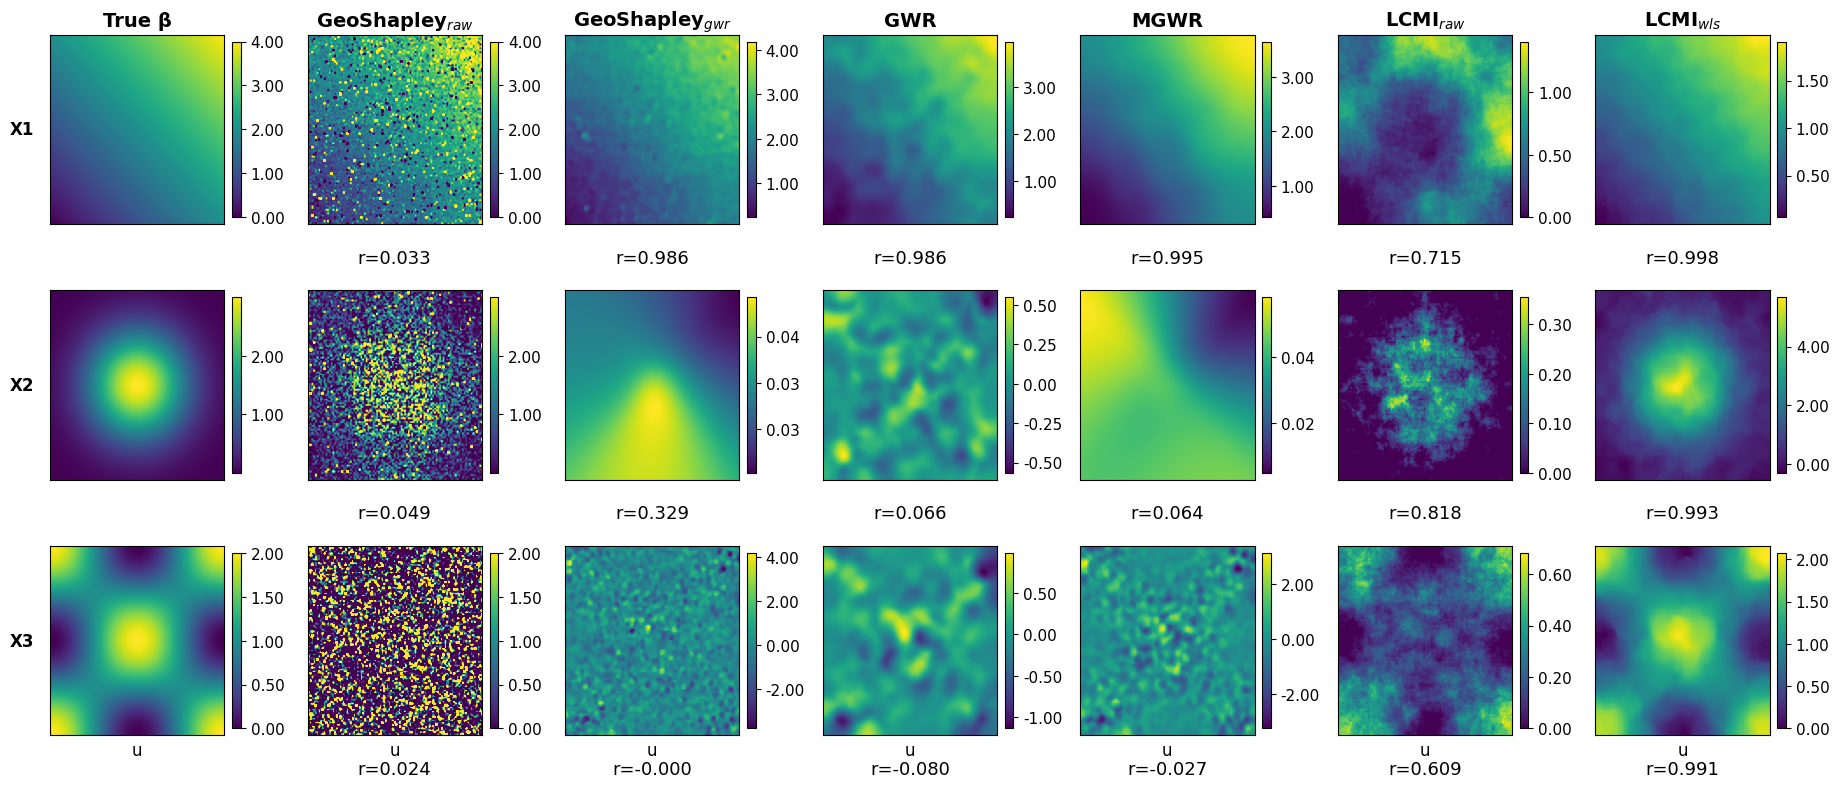

  Fig 1 saved


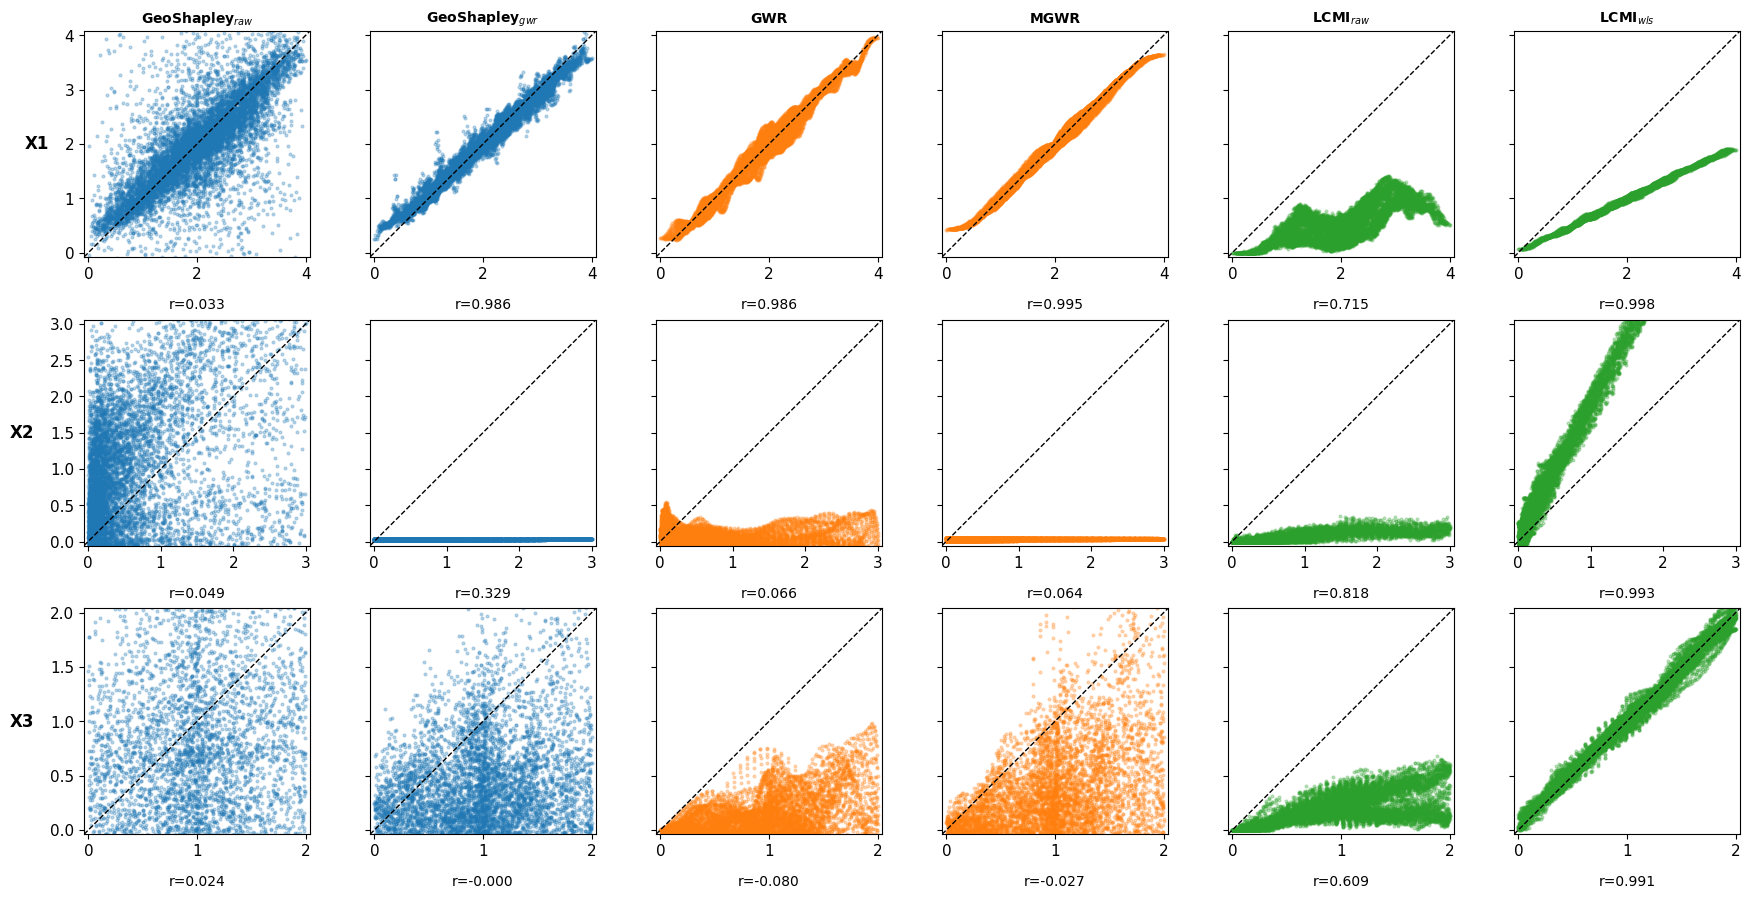

  Fig 2 saved


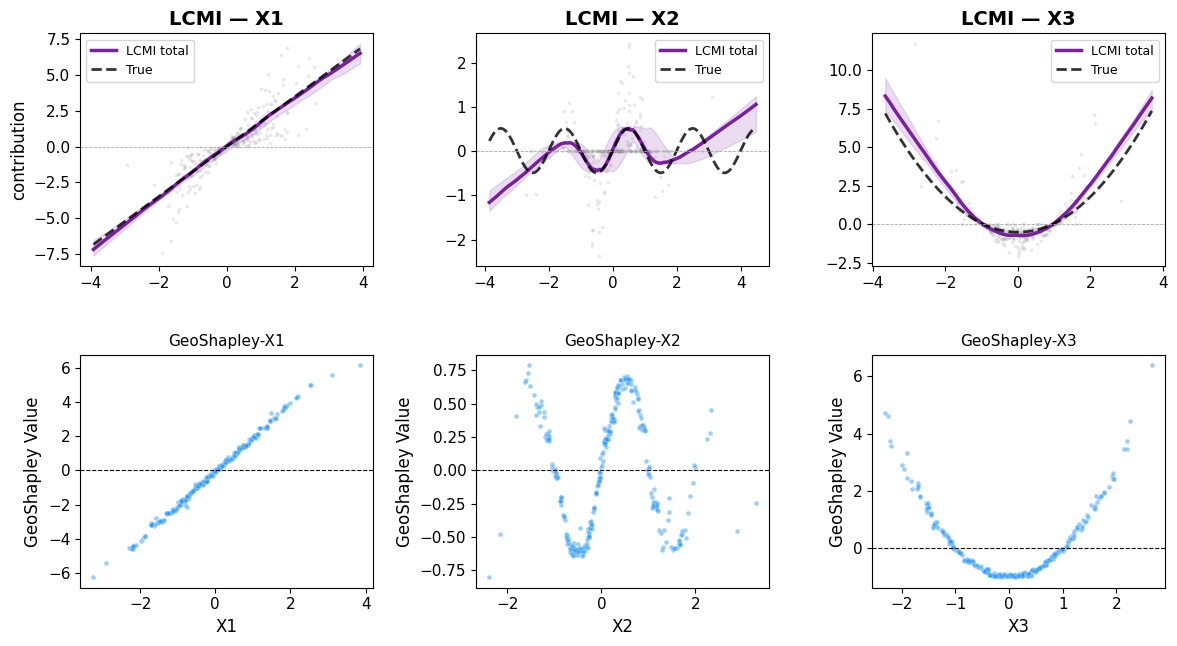

  Fig 3 saved

Model Comparison Table

  Model                  R²     Time   Beta    Min_est    Max_est   Pearson   Jacc@25%
  ──────────────────────────────────────────────────────────────────────────────────────────────────────────────
  LCMI_raw            0.824   9.149s     β₁      0.000      1.406     0.715      0.638
  LCMI_raw            0.824   9.149s     β₂      0.000      0.354     0.818      0.681
  LCMI_raw            0.824   9.149s     β₃      0.000      0.682     0.609      0.323
  LCMI_wls            0.954   9.149s     β₁      0.064      1.909     0.998      0.936
  LCMI_wls            0.954   9.149s     β₂     -0.285      5.675     0.993      0.942
  LCMI_wls            0.954   9.149s     β₃     -0.000      2.075     0.991      0.909
  Geoshapley_gwr      0.944  77.457s     β₁      0.242      4.184     0.986      0.872
  Geoshapley_gwr      0.944  77.457s     β₂      0.020      0.039     0.329      0.222
  Geoshapley_gwr      0.944  77.457s     β₃     -3.805      4.190

,Model,R²,Time(s),Beta,Min_est,Max_est,Pearson_r,Jaccard@25%
0,LCMI_raw,0.824,9.149,β₁,0.000,1.406,0.715,0.638
1,LCMI_raw,0.824,9.149,β₂,0.000,0.354,0.818,0.681
2,LCMI_raw,0.824,9.149,β₃,0.000,0.682,0.609,0.323
3,LCMI_wls,0.954,9.149,β₁,0.064,1.909,0.998,0.936
4,LCMI_wls,0.954,9.149,β₂,-0.285,5.675,0.993,0.942
5,LCMI_wls,0.954,9.149,β₃,-0.000,2.075,0.991,0.909
6,Geoshapley_gwr,0.944,77.457,β₁,0.242,4.184,0.986,0.872
7,Geoshapley_gwr,0.944,77.457,β₂,0.020,0.039,0.329,0.222
8,Geoshapley_gwr,0.944,77.457,β₃,-3.805,4.190,-0.000,0.172
9,Geoshapley_raw,0.944,77.457,β₁,-1064.290,1388.414,0.033,0.516


In [4]:
# ---------------------------
# Step 2: GeoShapley — tuned GBRT + get_svc(gwr) + get_svc(raw)
# ---------------------------
print("\n" + "=" * 65)
print("Step 2: GeoShapley (tuned GBRT, svc gwr + svc raw)")
print("=" * 65)

HAS_GEOSHAPLEY = False
try:
    from geoshapley import GeoShapleyExplainer

    HAS_GEOSHAPLEY = True
except Exception:
    print("  geoshapley not installed — GeoShapley surfaces will be zeros")

# Same predictors + coords as LCMI: raw X1,X2,X3 from df (not engineered basis)
X_geo_df = df[list(xlist) + [u_col, v_col]].copy()

model_surfaces = {}
run_time = {}
model_r2 = {}


def _zeros_surface():
    z = np.zeros(n, dtype=float)
    return {"b1": z.copy(), "b2": z.copy(), "b3": z.copy()}


def run_geoshapley_tuned_gwr():
    """Tuned GBRT, explain once; local betas from get_svc(gwr) and get_svc(raw)."""
    gs_model = GradientBoostingRegressor(n_estimators=200, max_depth=5, random_state=SEED)
    t0 = time.perf_counter()
    gs_model.fit(X_geo_df.values, Y)
    y_hat = gs_model.predict(X_geo_df.values)
    r2_gs = float(r2_score(Y, y_hat))

    bg_n = min(150, n)
    rng_bg = np.random.default_rng(SEED + 11)
    bg_idx = rng_bg.choice(n, size=bg_n, replace=False)
    background = X_geo_df.iloc[bg_idx].values.astype(float)
    predict_fn = lambda arr: gs_model.predict(np.asarray(arr, dtype=float))

    if not HAS_GEOSHAPLEY:
        elapsed = time.perf_counter() - t0
        return r2_gs, elapsed, _zeros_surface(), _zeros_surface(), None

    try:
        explainer = GeoShapleyExplainer(predict_fn, background, g=2, exact=True)
    except TypeError:
        explainer = GeoShapleyExplainer(predict_fn, background, g=2)

    gs_r = explainer.explain(X_geo_df, n_jobs=-1)
    elapsed = time.perf_counter() - t0

    try:
        svc_gwr = gs_r.get_svc([0, 1, 2], coef_type="gwr", include_primary=True, coords=coords)
    except Exception as ex:
        print(f"  get_svc(coef_type='gwr') failed: {ex}")
        svc_gwr = np.zeros((n, 3), dtype=float)

    surf_gwr = {
        "b1": np.asarray(svc_gwr[:, 0], dtype=float),
        "b2": np.asarray(svc_gwr[:, 1], dtype=float),
        "b3": np.asarray(svc_gwr[:, 2], dtype=float),
    }

    try:
        svc_raw = gs_r.get_svc([0, 1, 2], coef_type="raw", include_primary=True, coords=coords)
    except Exception as ex:
        print(f"  get_svc(coef_type='raw') failed: {ex}")
        svc_raw = np.zeros((n, 3), dtype=float)

    surf_raw = {
        "b1": np.asarray(svc_raw[:, 0], dtype=float),
        "b2": np.asarray(svc_raw[:, 1], dtype=float),
        "b3": np.asarray(svc_raw[:, 2], dtype=float),
    }
    return r2_gs, elapsed, surf_gwr, surf_raw, gs_r


if HAS_GEOSHAPLEY:
    r2_gs, elapsed, gs_surf_gwr, gs_surf_raw, gs_explain = run_geoshapley_tuned_gwr()
    run_time["GS_tuned"] = elapsed
    model_r2["GS_tuned"] = r2_gs
    model_surfaces["GS_tuned_gwr"] = gs_surf_gwr
    model_surfaces["GS_tuned_raw"] = gs_surf_raw
    print(f"  [tuned] R²(GBRT)={r2_gs:.4f}, time={elapsed:.1f}s  (get_svc gwr + raw)")
else:
    run_time["GS_tuned"] = np.nan
    model_r2["GS_tuned"] = np.nan
    model_surfaces["GS_tuned_gwr"] = _zeros_surface()
    model_surfaces["GS_tuned_raw"] = _zeros_surface()
    gs_explain = None


# ---------------------------
# Step 3: LCMI — single fit → LWS + WLS
# ---------------------------
print("\n" + "=" * 65)
print("Step 3: LCMI (one fit → LWS + WLS)")
print("=" * 65)

from lcmi import CMI
from mgwr.gwr import GWR, MGWR
from mgwr.sel_bw import Sel_BW

model = CMI(df, u=u_col, v=v_col, y=y_col, xlist=xlist, seed=SEED)
t0 = time.perf_counter()
model.fit()
run_time["LCMI"] = time.perf_counter() - t0

meta = model.result.meta
r2_lws = float(meta.get("r2", np.nan))
r2_wls = float(meta.get("r2_wls", np.nan))
df_out = model.df_out

model_r2["LCMI_raw"] = r2_lws
model_r2["LCMI_wls"] = r2_wls if np.isfinite(r2_wls) else r2_lws

model_surfaces["LCMI_raw"] = {
    "b1": df_out[f"{xlist[0]}_lws"].to_numpy(dtype=float),
    "b2": df_out[f"{xlist[1]}_lws"].to_numpy(dtype=float),
    "b3": df_out[f"{xlist[2]}_lws"].to_numpy(dtype=float),
}
model_surfaces["LCMI_wls"] = {
    "b1": df_out[f"{xlist[0]}_wls"].to_numpy(dtype=float),
    "b2": df_out[f"{xlist[1]}_wls"].to_numpy(dtype=float),
    "b3": df_out[f"{xlist[2]}_wls"].to_numpy(dtype=float),
}

print(f"  LCMI R² (LWS / base) = {r2_lws:.4f}")
if np.isfinite(r2_wls):
    print(f"  LCMI R² (WLS)       = {r2_wls:.4f}")
else:
    print("  LCMI R² (WLS)       = n/a")
print(f"  LCMI total time     = {run_time['LCMI']:.1f}s")

# ---------------------------
# Step 4: GWR / MGWR baseline on true transformed terms
# ---------------------------
print("\n" + "=" * 65)
print("Step 4: GWR / MGWR")
print("=" * 65)

gwr_X = np.column_stack([X1, X2, X3]).astype(float)
gwr_y = Y.reshape(-1, 1).astype(float)
gwr_coords = coords.astype(float)

# GWR
t0 = time.perf_counter()
try:
    gwr_bw = Sel_BW(gwr_coords, gwr_y, gwr_X).search()
    gwr_fit = GWR(gwr_coords, gwr_y, gwr_X, gwr_bw).fit()
    gwr_params = np.asarray(gwr_fit.params, float)
    if gwr_params.shape[1] == gwr_X.shape[1] + 1:
        gwr_params = gwr_params[:, 1:]
    gwr_pred = np.asarray(gwr_fit.predy, float).ravel()
    model_surfaces["GWR"] = {
        "b1": gwr_params[:, 0],
        "b2": gwr_params[:, 1],
        "b3": gwr_params[:, 2],
    }
    model_r2["GWR"] = float(r2_score(Y, gwr_pred))
    run_time["GWR"] = time.perf_counter() - t0
    print(f"  GWR: bw={gwr_bw}, R²={model_r2['GWR']:.4f}, time={run_time['GWR']:.1f}s")
except Exception as ex:
    run_time["GWR"] = np.nan
    model_r2["GWR"] = np.nan
    model_surfaces["GWR"] = _zeros_surface()
    print(f"  GWR failed: {ex}")

# MGWR
t0 = time.perf_counter()
try:
    mgwr_selector = Sel_BW(gwr_coords, gwr_y, gwr_X, multi=True)
    mgwr_bw = mgwr_selector.search()
    try:
        # Newer mgwr API: do not pass bw explicitly once selector has searched.
        mgwr_fit = MGWR(gwr_coords, gwr_y, gwr_X, selector=mgwr_selector).fit()
    except TypeError:
        # Older variants may still require bw.
        mgwr_fit = MGWR(gwr_coords, gwr_y, gwr_X, selector=mgwr_selector, bw=mgwr_bw).fit()

    mgwr_params = np.asarray(mgwr_fit.params, float)
    if mgwr_params.shape[1] == gwr_X.shape[1] + 1:
        mgwr_params = mgwr_params[:, 1:]
    if hasattr(mgwr_fit, "predy") and mgwr_fit.predy is not None:
        mgwr_pred = np.asarray(mgwr_fit.predy, float).ravel()
    else:
        mgwr_pred = mgwr_fit.params[:, 0] + np.sum(mgwr_params * gwr_X, axis=1)
    model_surfaces["MGWR"] = {
        "b1": mgwr_params[:, 0],
        "b2": mgwr_params[:, 1],
        "b3": mgwr_params[:, 2],
    }
    model_r2["MGWR"] = float(r2_score(Y, mgwr_pred))
    run_time["MGWR"] = time.perf_counter() - t0
    print(f"  MGWR: bw={mgwr_bw}, R²={model_r2['MGWR']:.4f}, time={run_time['MGWR']:.1f}s")
except Exception as ex:
    run_time["MGWR"] = np.nan
    model_r2["MGWR"] = np.nan
    model_surfaces["MGWR"] = _zeros_surface()
    print(f"  MGWR failed: {ex}")

FIG1_ORDER = ["GS_tuned_raw", "GS_tuned_gwr", "GWR", "MGWR", "LCMI_raw", "LCMI_wls"]
FIG2_ORDER = ["GS_tuned_raw", "GS_tuned_gwr", "GWR", "MGWR", "LCMI_raw", "LCMI_wls"]
TABLE_ORDER = ["LCMI_raw", "LCMI_wls", "GS_tuned_gwr", "GS_tuned_raw", "GWR", "MGWR"]

SURFACE_LABELS = {
    "GS_tuned_gwr": "GeoShapley$_{gwr}$",
    "GS_tuned_raw": "GeoShapley$_{raw}$",
    "GWR": "GWR",
    "MGWR": "MGWR",
    "LCMI_raw": "LCMI$_{raw}$",
    "LCMI_wls": "LCMI$_{wls}$",
}

MODEL_DISPLAY = {
    "GS_tuned_gwr": "Geoshapley_gwr",
    "GS_tuned_raw": "Geoshapley_raw",
    "LCMI_raw": "LCMI_raw",
    "LCMI_wls": "LCMI_wls",
    "GWR": "GWR",
    "MGWR": "MGWR",
}


def scale_true_curve(x_fine, y_true, y_target, X_arr):
    f_samp = np.interp(X_arr, x_fine, y_true)
    denom = float(np.dot(f_samp, f_samp)) + 1e-8
    a = float(np.dot(f_samp, y_target) / denom)
    b = float(np.mean(y_target) - a * np.mean(f_samp))
    return a * y_true + b


def _corr(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    m = np.isfinite(a) & np.isfinite(b)
    return float(pearsonr(a[m], b[m])[0]) if m.sum() >= 5 else np.nan


def _set_fig_style():
    plt.rcParams["axes.titlesize"] = 14
    plt.rcParams["axes.labelsize"] = 12
    plt.rcParams["xtick.labelsize"] = 11
    plt.rcParams["ytick.labelsize"] = 11


def _surface_grid(vals, grid_size):
    side = int(np.sqrt(len(vals)))
    return vals.reshape((side, side))


def _format_cbar_tick_labels(cbar):
    # Keep matplotlib default tick locations, only format labels to 2 decimals.
    cbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:.2f}"))


def plot_fig1():
    _set_fig_style()
    side = int(np.sqrt(n))
    columns = ["True β"] + [SURFACE_LABELS[k] for k in FIG1_ORDER]
    n_cols = len(columns)
    fig = plt.figure(figsize=(3.2 * n_cols, 9.1))
    gs = mgridspec.GridSpec(3, n_cols, figure=fig, wspace=0.35, hspace=0.35)

    truth_map = {"b1": beta1_true, "b2": beta2_true, "b3": beta3_true}
    row_labels = ["X1", "X2", "X3"]
    for ri, bk in enumerate(["b1", "b2", "b3"]):
        truth = truth_map[bk]
        t_lo = float(np.nanmin(truth))
        t_hi = float(np.nanmax(truth))

        ax = fig.add_subplot(gs[ri, 0])
        im = ax.imshow(_surface_grid(truth, side), origin="lower", aspect="auto")
        if ri == 0:
            ax.set_title(columns[0], fontweight="bold")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_ylabel(row_labels[ri], fontsize=12, fontweight="bold", rotation=0, labelpad=20, va="center")
        if ri == 2:
            ax.set_xlabel("u", fontsize=12)
        cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        _format_cbar_tick_labels(cbar)

        for ci, key in enumerate(FIG1_ORDER, start=1):
            ax = fig.add_subplot(gs[ri, ci])
            est = np.asarray(model_surfaces[key][bk], float)
            if key == "GS_tuned_raw":
                im = ax.imshow(
                    _surface_grid(est, side),
                    origin="lower",
                    aspect="auto",
                    vmin=t_lo,
                    vmax=t_hi,
                )
            else:
                im = ax.imshow(_surface_grid(est, side), origin="lower", aspect="auto")
            if ri == 0:
                ax.set_title(columns[ci], fontweight="bold")
            ax.set_xticks([])
            ax.set_yticks([])
            if ri == 2:
                ax.set_xlabel("u", fontsize=12)
            cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
            _format_cbar_tick_labels(cbar)

            pr = _corr(truth, est)
            ax.text(
                0.5,
                -0.13,
                f"r={pr:.3f}",
                transform=ax.transAxes,
                ha="center",
                va="top",
                fontsize=13,
                fontweight="normal",
            )

    plt.savefig(f"{PREFIX}_fig1_surfaces.png", dpi=DPI, bbox_inches="tight")
    plt.show()
    print("  Fig 1 saved")


plot_fig1()


def plot_fig2():
    _set_fig_style()
    truth_map = {"b1": beta1_true, "b2": beta2_true, "b3": beta3_true}
    model_names = list(FIG2_ORDER)
    n_models = len(model_names)
    fig, axes = plt.subplots(3, n_models, figsize=(3.0 * n_models, 9.0), sharex="row", sharey="row")
    if n_models == 1:
        axes = axes.reshape(3, 1)

    row_labels = ["X1", "X2", "X3"]
    color_map = {
        "GS_tuned_raw": "#1f77b4",
        "GS_tuned_gwr": "#1f77b4",
        "GWR": "#ff7f0e",
        "MGWR": "#ff7f0e",
        "LCMI_raw": "#2ca02c",
        "LCMI_wls": "#2ca02c",
    }

    for ri, bk in enumerate(["b1", "b2", "b3"]):
        truth = truth_map[bk]
        t_lo = float(np.nanmin(truth))
        t_hi = float(np.nanmax(truth))
        pad = (t_hi - t_lo) * 0.02 + 1e-9
        lim_lo, lim_hi = t_lo - pad, t_hi + pad

        for mi, mn in enumerate(model_names):
            ax = axes[ri, mi]
            est = np.asarray(model_surfaces[mn][bk], float)
            pr = _corr(truth, est)
            ax.scatter(truth, est, s=4, alpha=0.28, rasterized=True, color=color_map[mn])
            ax.plot([lim_lo, lim_hi], [lim_lo, lim_hi], "k--", lw=1.0)
            ax.set_xlim(lim_lo, lim_hi)
            ax.set_ylim(lim_lo, lim_hi)
            ax.set_aspect("equal", adjustable="box")

            if ri == 0:
                ax.set_title(SURFACE_LABELS[mn], fontsize=10, fontweight="bold")
            if mi == 0:
                ax.set_ylabel(row_labels[ri], fontsize=12, fontweight="bold", rotation=0, labelpad=20, va="center")
            if ri == 2:
                ax.set_xlabel("")

            ax.text(
                0.50,
                -0.18,
                f"r={pr:.3f}",
                transform=ax.transAxes,
                ha="center",
                va="top",
                fontsize=10,
                fontweight="normal",
            )

    plt.tight_layout()
    plt.savefig(f"{PREFIX}_fig2_scatter.png", dpi=DPI, bbox_inches="tight")
    plt.show()
    print("  Fig 2 saved")


plot_fig2()


# Fig 3: LCMI PDP | GeoShapley package partial_dependence_plots style (primary vs X); custom get_svc PDP row removed
def _boot_lowess(x, y, frac=0.25, n_pts=120, n_boot=40, seed=0):
    from numpy.random import default_rng

    def _lowess_curve(x0, y0):
        x0, y0 = np.asarray(x0, float), np.asarray(y0, float)
        order = np.argsort(x0)
        xs, ys = x0[order], y0[order]
        x_eval = np.linspace(xs.min(), xs.max(), n_pts)
        y_eval = np.zeros(n_pts)
        h = min(len(xs), max(int(len(xs) * frac), 5))
        for i, xe in enumerate(x_eval):
            dists = np.abs(xs - xe)
            idx = np.argpartition(dists, h - 1)[:h]
            d_local = dists[idx]
            dm = d_local.max() + 1e-8
            wgt = (1 - (d_local / dm) ** 3) ** 3
            x_local = xs[idx]
            y_local = ys[idx]
            try:
                sw = np.sqrt(wgt)
                A = np.column_stack([sw, x_local * sw])
                b = y_local * sw
                beta = np.linalg.lstsq(A, b, rcond=None)[0]
                y_eval[i] = beta[0] + beta[1] * xe
            except Exception:
                y_eval[i] = np.average(y_local, weights=wgt)
        return x_eval, y_eval

    rng = default_rng(seed)
    curves = []
    for _ in range(int(n_boot)):
        idx = rng.choice(len(x), size=len(x), replace=True)
        try:
            _, yc = _lowess_curve(np.asarray(x)[idx], np.asarray(y)[idx])
            curves.append(yc)
        except Exception:
            pass
    xev, ym = _lowess_curve(x, y)
    if not curves:
        return xev, ym, ym, ym
    curves = np.asarray(curves)
    return xev, np.median(curves, 0), np.percentile(curves, 10, 0), np.percentile(curves, 90, 0)


# LCMI row "True" overlay: DGP-style contribution with mean spatial β
TRUE_FN = {
    "X1": lambda x: x * float(np.mean(beta1_true)),
    "X2": lambda x: float(np.mean(beta2_true)) * np.sin(np.pi * x),
    "X3": lambda x: float(np.mean(beta3_true)) * (x**2),
}


def plot_fig3():
    _set_fig_style()
    fig = plt.figure(figsize=(14.0, 7.2))
    gs = mgridspec.GridSpec(2, 3, figure=fig, wspace=0.35, hspace=0.38)

    cmi_contrib = model.result.cmi_contrib
    pdp_cfg = [
        (X1, cmi_contrib[:, 0], "X1", TRUE_FN["X1"]),
        (X2, cmi_contrib[:, 1], "X2", TRUE_FN["X2"]),
        (X3, cmi_contrib[:, 2], "X3", TRUE_FN["X3"]),
    ]
    rng = np.random.default_rng(SEED)

    for ci, (X_arr, y_arr, nm, true_fn) in enumerate(pdp_cfg):
        ax = fig.add_subplot(gs[0, ci])
        xev, ymed, ylo, yhi = _boot_lowess(X_arr, y_arr, frac=0.25, n_pts=120, n_boot=40, seed=SEED + 10 + ci)
        ax.fill_between(xev, ylo, yhi, alpha=0.15, color="#7A1FA2")
        ax.plot(xev, ymed, color="#7A1FA2", lw=2.5, label="LCMI total")
        x_fine = np.linspace(np.min(X_arr), np.max(X_arr), 200)
        y_true = scale_true_curve(x_fine, true_fn(x_fine), y_arr, X_arr)
        ax.plot(x_fine, y_true, "k--", lw=2.0, alpha=0.8, label="True")
        idx_s = rng.choice(n, size=min(300, n), replace=False)
        ax.scatter(X_arr[idx_s], y_arr[idx_s], s=3, alpha=0.12, color="#888", rasterized=True)
        ax.axhline(0, color="#aaa", lw=0.6, ls="--")
        ax.set_title(f"LCMI — {nm}", fontweight="bold")
        ax.set_ylabel("contribution" if ci == 0 else "")
        ax.legend(fontsize=9)

    # Row 2: same as geoshapley.GeoShapleyResults.partial_dependence_plots() — scatter(X_j, primary[:,j])
    if gs_explain is not None:
        rng_p = np.random.default_rng(SEED + 99)
        for ci in range(3):
            ax = fig.add_subplot(gs[1, ci])
            ax.axhline(0, linestyle="--", color="black", lw=0.8)
            xv = X_geo_df.iloc[:, ci].to_numpy(dtype=float)
            yv = gs_explain.primary[:, ci]
            idx_p = rng_p.choice(n, size=min(300, n), replace=False)
            ax.scatter(
                xv[idx_p],
                yv[idx_p],
                s=12,
                color="#2196F3",
                edgecolors="white",
                lw=0.3,
                alpha=0.45,
                rasterized=True,
            )
            ax.set_ylabel("GeoShapley Value")
            ax.set_xlabel(xlist[ci])
            ax.set_title(f"GeoShapley-{xlist[ci]}", fontsize=11)
    else:
        for ci in range(3):
            ax = fig.add_subplot(gs[1, ci])
            ax.text(0.5, 0.5, "geoshapley unavailable", ha="center", va="center", transform=ax.transAxes)
            ax.set_axis_off()

    plt.savefig(f"{PREFIX}_fig3_pdp_compare.png", dpi=DPI, bbox_inches="tight")
    plt.show()
    print("  Fig 3 saved")


plot_fig3()


def _r2_for_surface_key(mn):
    if mn in ("GS_tuned_gwr", "GS_tuned_raw"):
        return model_r2.get("GS_tuned", np.nan)
    if mn == "GWR":
        return model_r2.get("GWR", np.nan)
    if mn == "MGWR":
        return model_r2.get("MGWR", np.nan)
    if mn == "LCMI_raw":
        return model_r2.get("LCMI_raw", np.nan)
    if mn == "LCMI_wls":
        return model_r2.get("LCMI_wls", np.nan)
    return np.nan


def _time_for_surface_key(mn):
    if mn in ("GS_tuned_gwr", "GS_tuned_raw"):
        return run_time.get("GS_tuned", np.nan)
    if mn == "GWR":
        return run_time.get("GWR", np.nan)
    if mn == "MGWR":
        return run_time.get("MGWR", np.nan)
    if mn.startswith("LCMI"):
        return run_time.get("LCMI", np.nan)
    return np.nan


def build_comparison_table():
    print("\n" + "=" * 65)
    print("Model Comparison Table")
    print("=" * 65)

    rows = []
    beta_items = [("b1", beta1_true, "β₁"), ("b2", beta2_true, "β₂"), ("b3", beta3_true, "β₃")]
    for mn in TABLE_ORDER:
        for bk, truth, blabel in beta_items:
            est = np.asarray(model_surfaces[mn][bk], float)
            pr = _corr(truth, est)

            top = max(1, int(len(truth) * 0.25))
            t_top = set(np.argsort(truth)[-top:])
            e_top = set(np.argsort(est)[-top:])
            jac = len(t_top & e_top) / len(t_top | e_top) if len(t_top | e_top) > 0 else 0.0

            rows.append(
                {
                    "Model": MODEL_DISPLAY[mn],
                    "Beta": blabel,
                    "R²": _r2_for_surface_key(mn),
                    "Time(s)": _time_for_surface_key(mn),
                    "Min_est": float(np.nanmin(est)),
                    "Max_est": float(np.nanmax(est)),
                    "Pearson_r": pr,
                    "Jaccard@25%": jac,
                }
            )

    tb = pd.DataFrame(
        rows,
        columns=["Model", "R²", "Time(s)", "Beta", "Min_est", "Max_est", "Pearson_r", "Jaccard@25%"],
    )

    num_cols = ["R²", "Time(s)", "Min_est", "Max_est", "Pearson_r", "Jaccard@25%"]
    tb[num_cols] = tb[num_cols].apply(pd.to_numeric, errors="coerce").round(3)

    print(f"\n  {'Model':<17} {'R²':>7} {'Time':>8} {'Beta':>6} {'Min_est':>10} {'Max_est':>10} {'Pearson':>9} {'Jacc@25%':>10}")
    print(f"  {'─'*110}")
    for _, r in tb.iterrows():
        t_str = f"{r['Time(s)']:.3f}s" if np.isfinite(r["Time(s)"]) else ""
        print(
            f"  {r['Model']:<17} {r['R²']:>7.3f} {t_str:>8} {r['Beta']:>6} {r['Min_est']:>10.3f} {r['Max_est']:>10.3f} {r['Pearson_r']:>9.3f} {r['Jaccard@25%']:>10.3f}"
        )

    tb.to_csv(f"{PREFIX}_comparison_table.csv", index=False, float_format="%.3f")
    print(f"\n  Table saved: {PREFIX}_comparison_table.csv")
    return tb


table = build_comparison_table()
table
